# WP12 — Kullanıcının hesap düzeltmesi sonrası ayrı S01 denemesi

Bu notebook yalnız çevrimdışı hazırlıktır. Kullanıcı önceki429 hatasını yanlış hesap anahtarına bağladı; bu neden kullanıcı beyanıdır, hesap API'sinden bağımsız doğrulanmadı. Önceki başarısız deneme, ham veriler ve bütün rezervler korunur. Yeni açıklama **NOT_RUN**; test fixture'ları sonuç değildir.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_corrected_account_preparation_v1'
F=ROOT/'reports/figures/WP12/openai_corrected_account_preparation_v1';F.mkdir(parents=True,exist_ok=True)
ready=json.loads((Q/'readiness_NOT_RUN.json').read_text(encoding='utf-8'))
display(pd.read_csv(Q/'comparison_real_and_NOT_RUN.csv'))
display(pd.DataFrame([{'alan':'Proje .env anahtarı VAR/YOK','sonuç':ready['project_dotenv_key_available']},
 {'alan':'Yeni gerçek API isteği','sonuç':0},{'alan':'Kredili hesabın doğrulanması','sonuç':'PENDING; offline hesap sorgusu yok'}]))


,experiment,status,detail,semantic_result,human_review
0,Gemma V1,FAIL,SCHEMA_OR_SOURCE_VALIDATION_FAILED,FAIL_ENGLISH,PENDING
1,Gemma V2,FAIL,TOKEN_COUNT_ALIGNMENT_FAILED,FAIL_ENGLISH,PENDING
2,Qwen3 4B,NOT_RUN,BLOCKED_HOST_RAM_AND_TOKEN_API_PREREQUISITES,NOT_RUN,PENDING
3,OpenAI S01 / first account,API_BILLING_BLOCKED_NO_MODEL_OUTPUT,HTTP429 credit_balance_exhausted,NOT_EVALUABLE_NO_OUTPUT,PENDING_NO_OUTPUT
4,OpenAI S01 / corrected account v1,NOT_RUN,USER_EXECUTOR_READY,NOT_RUN,PENDING


,alan,sonuç
0,Proje .env anahtarı VAR/YOK,True
1,Yeni gerçek API isteği,0
2,Kredili hesabın doğrulanması,PENDING; offline hesap sorgusu yok


**Yorum:** Eski Gemma başarısızlıkları, Qwen NOT_RUN ve OpenAI429 kaydı ayrı kalır. Yeni model, prompt veya kaynak geliştirmesi yapılmadı. Aynı S01 tekrarının amacı hesap/kimlik altyapısını düzeltmektir; bağımsız genelleme kanıtı değildir. Yeni yürütücü süreç ortamındaki olası eski key yerine yalnız proje .env alanını okur. Anahtar değeri/uzunluğu/prefix'i/hash'i gösterilmez.

## 1. Aynı dondurulmuş gerçek kaynak

In [2]:

import wp12_openai_adapter as a
sources=a.source_payload()['sources']
with pd.option_context('display.max_colwidth',None):
    display(pd.DataFrame(sources)[['physical_page','kind','quote_id','quote']])
print('Tam iki alıntı:',sum(len(x['quote']) for x in sources),'karakter; model:',a.build_request()['model'])


Tam iki alıntı: 537 karakter; model: gpt-5.4-mini


,physical_page,kind,quote_id,quote
0,1,identity,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n"
1,6,formulation,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n"


**Yorum:** DB00199, fiziksel1/6 ve iki özgün alıntı değişmemiştir. İstenen çıktı Türkçe, yalnız PDF kaynağına dayalıdır. Ürün/tuz/formülasyon eşdeğerliği veya GNN/PT/skor üretme yetkisi yoktur. reported_in_PDF ve predicted_by_GNN ayrımı korunur.

## 2. Eski ve yeni denemenin ortak bütçesi

,durum,HTTP,inference_rezerv,USD
0,Eski başarısız hesap / korunmuş rezerv,3,1,0.023
1,Yeni3HTTP+1inference olursa toplam / PLAN,6,2,0.046


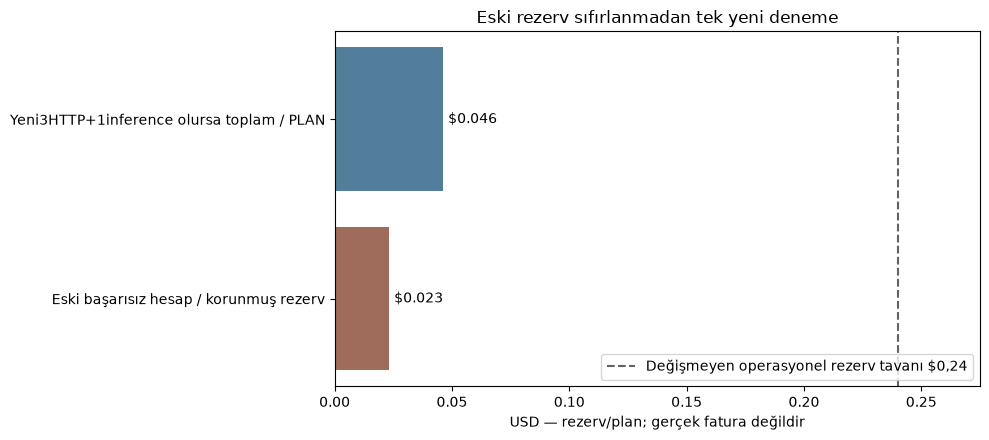

In [3]:

budget=pd.DataFrame([{'durum':'Eski başarısız hesap / korunmuş rezerv','HTTP':3,'inference_rezerv':1,'USD':.023},
    {'durum':'Yeni3HTTP+1inference olursa toplam / PLAN','HTTP':6,'inference_rezerv':2,'USD':.046}])
display(budget)
fig,ax=plt.subplots(figsize=(10,4.5))
bars=ax.barh(budget.durum,budget.USD,color=['#9f6b5b','#527e9c'])
ax.bar_label(bars,labels=[f'${x:.3f}' for x in budget.USD],padding=4)
ax.axvline(.24,color='#626262',linestyle='--',label='Değişmeyen operasyonel rezerv tavanı $0,24')
ax.set(xlim=(0,.275),xlabel='USD — rezerv/plan; gerçek fatura değildir',title='Eski rezerv sıfırlanmadan tek yeni deneme')
ax.legend(loc='lower right');plt.tight_layout();plt.savefig(F/'01_preserved_and_projected_reservations.png',dpi=160);plt.show()


**Yorum:** İlk hesabın UNKNOWN gerçek maliyeti sıfır varsayılmaz; tam rezerv taşınır. Aynı pilotun10 toplam HTTP/10 inference ve<$0,25 sınırı her çağrı öncesi bütün ledger'lar üzerinden denetlenir. Yeni deneme tam ilerlerse toplam6 HTTP/2 inference rezervi=$0,046 olur. Yeni key bütçe sıfırlama anlamına gelmez. Eski dört-vaka HTTP planına fazladan üç çağrı eklenmesi kalan kapasiteyi azaltır; diğer senaryolar bu yürütücüde açılmaz.

## 3. Teknik kanıt ve durma noktası

In [4]:

display(pd.DataFrame([json.loads((Q/'test_summary.json').read_text(encoding='utf-8'))]))
display(pd.DataFrame([json.loads((Q/'PowerShell_parse_and_hash.json').read_text(encoding='utf-8'))]))
display(pd.DataFrame([{'kontrol':k,'gerçek_yeni_durum':'NOT_RUN / insan PENDING'} for k in
    ['JSON Schema','Türkçe açıklama','PDF kaynak sadakati','quote-ID/sayfa','token/usage/maliyet','tam model snapshot/request-ID']]))


,tests,returncode,status,real_API_requests,fixtures
0,18,0,PASS,0,TEST_ONLY; socket disabled


,syntax_error_count,version,executed,policy_client_pins_match,script_sha256
0,0,5.1.26100.9711,False,True,b3d020ad8a453834ff0629148a7f07d1870fb69d75c2a7c7e253aeaf90dc42d3


,kontrol,gerçek_yeni_durum
0,JSON Schema,NOT_RUN / insan PENDING
1,Türkçe açıklama,NOT_RUN / insan PENDING
2,PDF kaynak sadakati,NOT_RUN / insan PENDING
3,quote-ID/sayfa,NOT_RUN / insan PENDING
4,token/usage/maliyet,NOT_RUN / insan PENDING
5,tam model snapshot/request-ID,NOT_RUN / insan PENDING


**Karar:** Yeni scope proje-geneli tek-attempt atomik kilit taşır; aynı komut ikinci üretim isteği gönderemez. Eski billing-stop ve slotlar değişmeden durur. V1 client/adaptör aynen kullanılır; yalnız credential kaynağı, yeni çıktı scope'u ve tüm-hesap bütçe kapısı eklenir. Normal kullanıcı PowerShell'i gerçek çalışmayı yapar. Kaynaklı çıktı alınırsa şema/uygulama/dil/kaynak sadakati ve gerçek usage ayrı değerlendirilecektir; insan semantik incelemesi olmadan yayın yoktur. Yeni API isteği,19×3, eğitim veya WP13 bu notebook'ta yoktur.

Resmî değişmeyen fiyat/model bilgisi: [OpenAI Docs](https://developers.openai.com/api/docs/models/gpt-5.4-mini).